# Lab 2 — What Did the Campaign Deliver?
Name: Alexander Zavadskyi | Group: KM-41

## Setup

In [1]:
import importlib.util, subprocess, sys
required = ['kagglehub', 'pyarrow', 'pandas', 'numpy', 'matplotlib']
missing = [p for p in required if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")
for df in [programs, viewings, commercials]:
    df['start_ts'] = pd.to_datetime(df['start_ts'])
    if 'end_ts' in df: df['end_ts'] = pd.to_datetime(df['end_ts'])
daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.normalize()
BIG = {'CBS', 'NBC', 'ABC', 'FOX', 'FNC'}
answers = {}
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
print('Dataset version: 3')

C:\Users\leks\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset version: 3


## Task 1.1 — Size

In [2]:
campaign = commercials.loc[commercials.brand.eq('BRAND_A')].copy()
assert commercials.ad_airing_id.is_unique and len(campaign) == 300
print("Spots:", len(commercials))
print("Pods:", commercials.pod_id.nunique())
print("Brands:", commercials.brand.nunique())
print("Categories:", commercials.category.nunique())
print("BRAND_A spots:", len(campaign))
display(campaign.groupby('network_code').size().rename('BRAND_A spots').to_frame())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,BRAND_A spots
network_code,
ABC,29
BRAVO,33
CBS,22
FNC,40
FOOD,33
FOX,13
FX,38
HGTV,39
HIST,37


## Task 1.2 — Ad load

In [3]:
# Split each spot at clock-hour boundaries, including any seconds after midnight.
segments = []
for spot in commercials.itertuples(index=False):
    t = spot.start_ts
    end = t + pd.Timedelta(seconds=spot.length_sec)
    while t < end:
        hour = t.floor('h')
        stop = min(end, hour + pd.Timedelta(hours=1))
        segments.append((spot.network_code, hour, (stop-t).total_seconds()))
        t = stop
hourly_ads = pd.DataFrame(segments, columns=['network_code','clock_hour','seconds'])
hourly_ads = hourly_ads.groupby(['network_code','clock_hour']).seconds.sum()
assert np.isclose(hourly_ads.sum(), commercials.length_sec.sum())
ad_load = hourly_ads.groupby('network_code').agg(['mean','size'])
ad_load.columns = ['ad seconds per hour','hours carrying ads']
ad_load['ad minutes per hour'] = ad_load.pop('ad seconds per hour') / 60
display(ad_load.round(1))
print("Heaviest ad load:", ad_load['ad minutes per hour'].idxmax())

,hours carrying ads,ad minutes per hour
network_code,,
ABC,353,11.700
BRAVO,623,13.400
CBS,429,12.100
FNC,743,15.600
FOOD,621,13.100
FOX,196,11.800
FX,621,12.900
HGTV,621,13.300
HIST,622,13.200


Heaviest ad load: FNC


**Answer:** Broadcast networks have local-station hours whose breaks are sold locally and are excluded from this national ad log. Paid programming and the vice-presidential debate also have no commercials in this dataset. The average above includes only clock hours with national ads, rather than treating all missing hours as zero.

## Task 1.3 — Price everything

In [4]:
priced = commercials.merge(programs[['telecast_id','program_name']], on='telecast_id', validate='many_to_one')
shifted = priced.start_ts - pd.Timedelta(hours=6)
priced['broadcast_date'] = shifted.dt.normalize()
priced['broadcast_weekday'] = shifted.dt.dayofweek
priced['broadcast_minute'] = shifted.dt.hour*60 + shifted.dt.minute + shifted.dt.second/60
program_rates = rate_card.loc[rate_card.program_name.notna()]
priced = priced.merge(program_rates[['network_code','program_name','daypart','cost_30s_usd']],
                      on=['network_code','program_name'], how='left', validate='many_to_one')
priced = priced.rename(columns={'daypart':'selling_daypart'})
priced['program_row'] = priced.cost_30s_usd.notna()
time_matches = np.zeros(len(priced), dtype=int)
def clock_minute(t):
    h,m = map(int,t.split(':'))
    return h*60+m-360
for r in rate_card.loc[rate_card.program_name.isna()].itertuples():
    mask = (priced.network_code.eq(r.network_code)
            & priced.broadcast_weekday.isin(r.weekdays)
            & priced.broadcast_minute.ge(clock_minute(r.start_time))
            & priced.broadcast_minute.lt(clock_minute(r.end_time)))
    time_matches += mask.to_numpy()
    fill = mask & ~priced.program_row
    priced.loc[fill,'selling_daypart'] = r.daypart
    priced.loc[fill,'cost_30s_usd'] = r.cost_30s_usd
assert (time_matches == 1).all(), 'Time rows must cover each spot exactly once'
priced['cost_usd'] = priced.cost_30s_usd * priced.length_sec / 30
print("Spots without a price:", int(priced.cost_usd.isna().sum()))
assert priced.cost_usd.notna().all() and len(priced) == len(commercials)
value = priced.groupby('network_code').cost_usd.sum().to_frame('rate-card value (USD M)')
sport_value = priced.loc[priced.program_row].groupby('network_code').cost_usd.sum()
value['share from program rows'] = sport_value.reindex(value.index, fill_value=0) / value.iloc[:,0]
value.iloc[:,0] /= 1e6
display(value.round(3))
campaign = priced.loc[priced.brand.eq('BRAND_A')].copy().set_index('ad_airing_id', drop=False).rename_axis(None)

Spots without a price: 0


,rate-card value (USD M),share from program rows
network_code,,
ABC,708.787,0.432
BRAVO,25.313,0.000
CBS,818.778,0.230
FNC,315.845,0.000
FOOD,42.149,0.000
FOX,696.173,0.835
FX,42.506,0.000
HGTV,58.103,0.000
HIST,40.085,0.000


Program rows take precedence over clock-based prices. The requested program-row share includes NBC Saturday Night Live as well as sports, because it is also sold by program in the supplied rate card.

## Task 2.1 — Delivery

In [5]:
# Stable persons only; use the spot broadcast day's in-tab weight, never a guest ID.
person_dw = daily_weights.loc[daily_weights.resp_type.isin(['R','L'])].copy()
assert not person_dw.duplicated(['respondent_id','broadcast_date']).any()
monthly_w = person_dw.groupby('respondent_id').weight.mean()
age = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)].set_index('respondent_id').value
female = set(viewer_attributes.loc[viewer_attributes.attr_id.eq(202),'respondent_id'])
target = set(age.loc[age.between(18,49)].index) & set(monthly_w.index)
women1834 = set(age.loc[age.between(18,34)].index) & female & set(monthly_w.index)
person_sessions = viewings.loc[viewings.resp_type.isin(['R','L'])]
sessions = {net:g for net,g in person_sessions.groupby('network_code')}
records = []
for s in campaign.itertuples(index=False):
    g = sessions[s.network_code]
    ids = g.loc[g.start_ts.le(s.start_ts) & g.end_ts.gt(s.start_ts),'respondent_id'].unique()
    records.extend((s.ad_airing_id, int(i), s.broadcast_date) for i in ids)
exposures = pd.DataFrame(records, columns=['ad_airing_id','respondent_id','broadcast_date'])
exposures = exposures.merge(person_dw[['respondent_id','broadcast_date','weight']],
                            on=['respondent_id','broadcast_date'], how='left', validate='many_to_one')
assert exposures.weight.notna().all()
assert not exposures.duplicated(['ad_airing_id','respondent_id']).any()
exposures['on_target'] = exposures.respondent_id.isin(target)
exposures['network_code'] = exposures.ad_airing_id.map(campaign.network_code)
daily_universe = person_dw.groupby('broadcast_date').weight.sum()
daily_target = person_dw.loc[person_dw.respondent_id.isin(target)].groupby('broadcast_date').weight.sum()
campaign['p2_imp'] = exposures.groupby('ad_airing_id').weight.sum().reindex(campaign.index, fill_value=0)
campaign['target_imp'] = exposures.loc[exposures.on_target].groupby('ad_airing_id').weight.sum().reindex(campaign.index, fill_value=0)
campaign['p2_rating'] = campaign.p2_imp / campaign.broadcast_date.map(daily_universe) * 100
campaign['target_rating'] = campaign.target_imp / campaign.broadcast_date.map(daily_target) * 100
def reach(ids, audience=None):
    universe = monthly_w if audience is None else monthly_w.loc[monthly_w.index.isin(audience)]
    return universe.loc[universe.index.isin(ids)].sum() / universe.sum()*100
reached = set(exposures.respondent_id)
p2_reach, target_reach = reach(reached), reach(reached,target)
p2_imp, target_imp = campaign.p2_imp.sum(), campaign.target_imp.sum()
p2_grp, target_grp = campaign.p2_rating.sum(), campaign.target_rating.sum()
print("P2+ impressions (M):", f'{p2_imp/1e6:.1f}')
print("P2+ GRPs:", f'{p2_grp:.1f}')
print("P2+ reach (%):", f'{p2_reach:.1f}')
print("P2+ average frequency:", f'{p2_grp/p2_reach:.1f}')
print("A18-49 impressions (M):", f'{target_imp/1e6:.1f}')
print("A18-49 GRPs:", f'{target_grp:.1f}')
print("A18-49 reach (%):", f'{target_reach:.1f}')
print("A18-49 average frequency:", f'{target_grp/target_reach:.1f}')

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


Reach uses each person’s mean weight across their in-tab days, including people with no campaign exposure in its denominator. Frequency follows the handout’s GRPs ÷ reach definition; daily and monthly weights can make it differ slightly from the mean of individual exposure counts.

## Task 2.2 — Frequency distribution

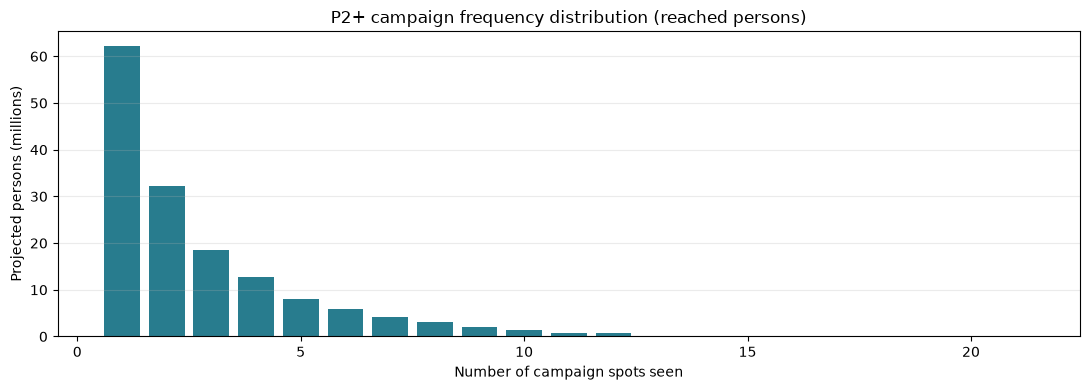

Share of impressions at 5+ exposures: 0.444


In [6]:
frequency = exposures.groupby('respondent_id').size().rename('exposures').to_frame()
frequency['monthly_weight'] = monthly_w.reindex(frequency.index)
dist = frequency.groupby('exposures').monthly_weight.sum()/1e6
dist = dist.reindex(range(1,int(dist.index.max())+1),fill_value=0)
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(dist.index,dist.values,color='#287c8e')
ax.set(xlabel='Number of campaign spots seen',ylabel='Projected persons (millions)',
       title='P2+ campaign frequency distribution (reached persons)')
ax.grid(axis='y',alpha=.25)
plt.tight_layout()
plt.show()
heavy_ids = set(frequency.index[frequency.exposures.ge(5)])
# Actual campaign impressions use broadcast-day weights, as in Task 2.1.
heavy_share = exposures.loc[exposures.respondent_id.isin(heavy_ids),'weight'].sum()/p2_imp
print("Share of impressions at 5+ exposures:", f'{heavy_share:.3f}')
answers['frequency'] = f'The average frequency is {p2_grp/p2_reach:.1f}, but individual counts range from 1 to {int(dist.index.max())}. People with five or more exposures account for {heavy_share:.3f} of impressions. The histogram reveals the concentration and spread hidden by one average, so the average alone is an incomplete summary.'

**Answer:** The average frequency is 3.0, but individual counts range from 1 to 21. People with five or more exposures account for 0.444 of impressions. The histogram reveals the concentration and spread hidden by one average, so the average alone is an incomplete summary.

## Task 2.3 — On target?

In [7]:
target_share = target_imp/p2_imp
population_share = monthly_w.loc[monthly_w.index.isin(target)].sum()/monthly_w.sum()
print("Share of impressions on A18-49:", f'{target_share:.3f}')
network = campaign.groupby('network_code').agg(spots=('ad_airing_id','size'), cost_usd=('cost_usd','sum'),
    p2_imp=('p2_imp','sum'), target_imp=('target_imp','sum'))
network['target_share'] = network.target_imp/network.p2_imp
network['target_surplus'] = network.target_imp-population_share*network.p2_imp
display(network[['target_share','target_surplus']].rename(columns={'target_surplus':'target impressions above population-share benchmark'}).round(3))
direction = 'under-delivered' if target_share < population_share else 'over-delivered'
low = network.nsmallest(3,'target_surplus')
high = network.nlargest(3,'target_surplus')
answers['target'] = f'The plan {direction}: A18–49 received {target_share:.3f} of impressions versus its {population_share:.3f} share of the monthly P2+ universe. The largest negative contributions relative to that benchmark came from {", ".join(low.index)}; the strongest positive contributions came from {", ".join(high.index)}. These contributions account for both a network’s audience composition and its campaign volume.'

Share of impressions on A18-49: 0.194


,target_share,target impressions above population-share benchmark
network_code,,
ABC,0.180,-22738603.229
BRAVO,0.554,673406.731
CBS,0.154,-23828294.903
FNC,0.047,-21655900.623
FOOD,0.316,-1006311.462
FOX,0.242,-13715830.861
FX,0.651,1957286.416
HGTV,0.306,-2843212.395
HIST,0.202,-2714332.251


**Answer:** The plan under-delivered: A18–49 received 0.194 of impressions versus its 0.422 share of the monthly P2+ universe. The largest negative contributions relative to that benchmark came from CBS, ABC, FNC; the strongest positive contributions came from FX, BRAVO, FOOD. These contributions account for both a network’s audience composition and its campaign volume.

## Task 3.1 — Cost

In [8]:
cost = campaign.cost_usd.sum()
p2_cpm, target_cpm = cost/p2_imp*1000, cost/target_imp*1000
p2_cpp, target_cpp = cost/p2_grp, cost/target_grp
print("Campaign cost (USD):", f'{cost:.0f}')
print("P2+ CPM (USD):", f'{p2_cpm:.2f}')
print("P2+ CPP (USD):", f'{p2_cpp:.0f}')
print("A18-49 CPM (USD):", f'{target_cpm:.2f}')
print("A18-49 CPP (USD):", f'{target_cpp:.0f}')

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [9]:
network['P2+ CPM (USD)'] = network.cost_usd/network.p2_imp*1000
network['A18-49 CPM (USD)'] = network.cost_usd/network.target_imp*1000
table = network[['spots','cost_usd']].copy()
table['P2+ impressions (M)'] = network.p2_imp/1e6
table['A18-49 impressions (M)'] = network.target_imp/1e6
table[['P2+ CPM (USD)','A18-49 CPM (USD)']] = network[['P2+ CPM (USD)','A18-49 CPM (USD)']]
display(table.style.format({'spots':'{:.0f}','cost_usd':'{:.0f}', 'P2+ impressions (M)':'{:.1f}',
    'A18-49 impressions (M)':'{:.1f}', 'P2+ CPM (USD)':'{:.2f}', 'A18-49 CPM (USD)':'{:.2f}'}))
spend_leaders = network.nlargest(3,'cost_usd')
cheapest = network.nsmallest(3,'A18-49 CPM (USD)')
answers['network_cost'] = 'The largest spending allocations were ' + ', '.join(f'{i} (${r.cost_usd:.0f}, {r.cost_usd/cost:.1%} of budget)' for i,r in spend_leaders.iterrows()) + '. The cheapest target impressions came from ' + ', '.join(f'{i} (${r["A18-49 CPM (USD)"]:.2f} CPM)' for i,r in cheapest.iterrows()) + '. CPM measures gross impressions, so it does not by itself establish incremental reach.'

,spots,cost_usd,P2+ impressions (M),A18-49 impressions (M),P2+ CPM (USD),A18-49 CPM (USD)
network_code,,,,,,
ABC,29,1625700,94.2,17.0,17.26,95.69
BRAVO,33,49610,5.1,2.8,9.76,17.61
CBS,22,1488700,89.0,13.7,16.73,108.72
FNC,40,526300,57.8,2.7,9.11,193.70
FOOD,33,96620,9.5,3.0,10.19,32.29
FOX,13,2434700,76.3,18.4,31.93,132.03
FX,38,92200,8.5,5.6,10.82,16.61
HGTV,39,230000,24.7,7.6,9.33,30.45
HIST,37,79640,12.3,2.5,6.46,32.05


**Answer:** The largest spending allocations were FOX ($2434700, 32.8% of budget), ABC ($1625700, 21.9% of budget), CBS ($1488700, 20.1% of budget). The cheapest target impressions came from FX ($16.61 CPM), BRAVO ($17.61 CPM), HGTV ($30.45 CPM). CPM measures gross impressions, so it does not by itself establish incremental reach.

## Task 3.3 — Guarantee

In [10]:
owed = max(0,150-p2_grp)
print("Guarantee met:", bool(p2_grp >= 150))
print("Make-good GRPs owed:", f'{owed:.1f}')
print("Value of make-goods (USD):", f'{owed*p2_cpp:.0f}')

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [11]:
big_ids = set(exposures.loc[exposures.network_code.isin(BIG),'respondent_id'])
small_ids = set(exposures.loc[~exposures.network_code.isin(BIG),'respondent_id'])
big_reach, small_reach = reach(big_ids), reach(small_ids)
overlap = reach(big_ids & small_ids)
independent = big_reach*small_reach/100
added = reach(small_ids-big_ids)
assert np.isclose(p2_reach, big_reach+small_reach-overlap)
big_cost = network.loc[network.index.isin(BIG),'cost_usd'].sum()
small_cost = cost-big_cost
small_cpp_reach, big_cpp_reach = small_cost/added, big_cost/big_reach
print("Reach, big networks (%):", f'{big_reach:.1f}')
print("Reach, small networks (%):", f'{small_reach:.1f}')
print("Reach, whole campaign (%):", f'{p2_reach:.1f}')
print("Overlap (%):", f'{overlap:.1f}')
print("Overlap if independent (%):", f'{independent:.1f}')
print("Reach added by small networks (points):", f'{added:.1f}')
print("Cost per added reach point, small (USD):", f'{small_cpp_reach:.0f}')
print("Cost per reach point, big (USD):", f'{big_cpp_reach:.0f}')
conditional = overlap/small_reach*100
answers['overlap'] = f'Reach does not add because {overlap:.1f}% of P2+ saw spots in both groups and would be counted twice. Observed overlap is {overlap:.1f}% versus {independent:.1f}% under independence; {conditional:.1f}% of small-network viewers were reached by big networks, compared with {big_reach:.1f}% of all P2+. Shared viewing habits and heavier TV consumption can create this dependence; this panel does not identify a causal explanation. Small networks added {added:.1f} reach points at ${small_cpp_reach:.0f} per point versus ${big_cpp_reach:.0f} for big-network reach, making them {"more" if small_cpp_reach<big_cpp_reach else "less"} economical on this comparison. The small-network figure is incremental to big networks, while the big-network figure is standalone.'

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Reach does not add because 8.7% of P2+ saw spots in both groups and would be counted twice. Observed overlap is 8.7% versus 4.9% under independence; 70.2% of small-network viewers were reached by big networks, compared with 39.8% of all P2+. Shared viewing habits and heavier TV consumption can create this dependence; this panel does not identify a causal explanation. Small networks added 3.7 reach points at $148706 per point versus $172456 for big-network reach, making them more economical on this comparison. The small-network figure is incremental to big networks, while the big-network figure is standalone.

## Task 5 — How sure are we?

In [12]:
campaign['panelists'] = exposures.groupby('ad_airing_id').respondent_id.nunique().reindex(campaign.index,fill_value=0)
daily_n = person_dw.groupby('broadcast_date').respondent_id.nunique()
p = campaign.p2_rating/100
campaign['SE'] = np.sqrt(p*(1-p)/campaign.broadcast_date.map(daily_n))*100
# SE/rating is undefined at a zero-cell, not zero. Report its exclusion explicitly.
campaign['relative_SE'] = campaign.SE/campaign.p2_rating.replace(0,np.nan)
reliability = campaign.groupby('network_code').agg(median_panelists=('panelists','median'),
    median_relative_SE=('relative_SE','median'),zero_cell_spots=('panelists',lambda x:int(x.eq(0).sum())))
display(reliability.round(3))
big_se = campaign.loc[campaign.network_code.isin(BIG),'relative_SE'].median()
small_se = campaign.loc[~campaign.network_code.isin(BIG),'relative_SE'].median()
zero = int(campaign.panelists.eq(0).sum())
w_counts = exposures.loc[exposures.respondent_id.isin(women1834)].groupby('ad_airing_id').size().reindex(campaign.index,fill_value=0)
wzero = int(w_counts.eq(0).sum())
print("Spots seen by no panelist:", zero)
print("Median relative SE, big networks:", f'{big_se:.3f}')
print("Median relative SE, small networks:", f'{small_se:.3f}')
print("W18-34 zero-cell spots:", wzero)
answers['uncertainty'] = f'{zero} spots have no observed R/L person and therefore a projected P2+ rating of zero. A zero-cell is absence of observed panel exposure, not proof of no real audience; sparse small-network samples make such estimates unstable. Relative SE is undefined for zero ratings, so the medians exclude those cells and the table reports their counts separately. There are {wzero} W18–34 zero-cells among 300 spots: I would avoid presenting their per-spot ratings as precise estimates, report the sample counts, and prefer pooled campaign/network estimates or a larger sample. The requested simple-random-sample SE ignores weighting, panel dependence and design effects and should be treated as a lower bound; even a computed zero SE at p=0 is not evidence of certainty.'

,median_panelists,median_relative_SE,zero_cell_spots
network_code,,,
ABC,57.000,0.123,0
BRAVO,3.000,0.540,3
CBS,69.000,0.113,0
FNC,31.000,0.164,0
FOOD,5.000,0.423,2
FOX,145.000,0.080,0
FX,5.500,0.423,4
HGTV,11.000,0.301,0
HIST,5.000,0.460,1


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** 10 spots have no observed R/L person and therefore a projected P2+ rating of zero. A zero-cell is absence of observed panel exposure, not proof of no real audience; sparse small-network samples make such estimates unstable. Relative SE is undefined for zero ratings, so the medians exclude those cells and the table reports their counts separately. There are 171 W18–34 zero-cells among 300 spots: I would avoid presenting their per-spot ratings as precise estimates, report the sample counts, and prefer pooled campaign/network estimates or a larger sample. The requested simple-random-sample SE ignores weighting, panel dependence and design effects and should be treated as a lower bound; even a computed zero SE at p=0 is not evidence of certainty.

## Bonus

In [13]:
# A budget-feasible illustrative reallocation of exactly 20 :30 spots.
# Choose an observed network/daypart with at least five campaign spots; use its
# mean target delivery rather than cherry-picking an individual replacement airing.
groups = campaign.groupby(['network_code','selling_daypart']).agg(
    spots=('ad_airing_id','size'),unit_cost=('cost_usd','mean'),mean_target_imp=('target_imp','mean'))
groups['target_CPM'] = groups.unit_cost/groups.mean_target_imp*1000
remove = campaign.sort_values(['cost_usd','ad_airing_id'],ascending=[False,True]).head(20)
released = remove.cost_usd.sum()
candidates = groups.loc[(groups.spots>=5) & (groups.mean_target_imp>0) & (groups.unit_cost*20<=released)]
choice = candidates.sort_values('target_CPM').iloc[0]
chosen_network, chosen_daypart = choice.name
replacement_cost = choice.unit_cost*20
replacement_imp = choice.mean_target_imp*20
new_cost = cost-released+replacement_cost
new_imp = target_imp-remove.target_imp.sum()+replacement_imp
new_cpm = new_cost/new_imp*1000
assert (campaign.length_sec==30).all() and new_cpm<target_cpm
display(remove.groupby(['network_code','selling_daypart']).agg(spots=('ad_airing_id','size'),released_usd=('cost_usd','sum')))
display(pd.DataFrame({'scenario':['Original campaign','Illustrative revised campaign'],
    'cost (USD)':[cost,new_cost],'A18-49 impressions (M)':[target_imp/1e6,new_imp/1e6],
    'A18-49 CPM (USD)':[target_cpm,new_cpm]}).round(2))
answers['bonus'] = f'Move the 20 most expensive :30 spots listed above (budget ${released:.0f}) to 20 :30 spots on {chosen_network}, {chosen_daypart}, at ${choice.unit_cost:.0f} each, spending ${replacement_cost:.0f} and leaving ${released-replacement_cost:.0f} unspent. The {int(choice.spots)} observed campaign spots in that network/daypart averaged {choice.mean_target_imp/1e6:.3f} million A18–49 impressions each, implying {replacement_imp/1e6:.1f} million replacement impressions. Holding other spots fixed, projected target CPM falls from ${target_cpm:.2f} to ${new_cpm:.2f}, with total spend ${new_cost:.0f} and target impressions {new_imp/1e6:.1f} million. This is an in-sample planning scenario assuming comparable future delivery and available inventory, not a guarantee of incremental reach; sparse cells and repeated viewers require validation before buying.'

spots  released_usd
network_code selling_daypart                                   
ABC          Prime                              1    151000.000
             Weekend Prime                      2    347600.000
CBS          NFL on CBS                         2    445200.000
             Prime                              2    357600.000
             Sunday Prime                       1    202400.000
FOX          College Football                   4    547200.000
             MLB Postseason & World Series      4   1320800.000
             NFL on FOX                         2    347200.000
NBC          Prime                              2    346800.000

,scenario,cost (USD),A18-49 impressions (M),A18-49 CPM (USD)
0,Original campaign,7420270.000,81.070,91.530
1,Illustrative revised campaign,3376470.000,53.910,62.640


**Answer:** Move the 20 most expensive :30 spots listed above (budget $4065800) to 20 :30 spots on FX, Daytime Movies, at $1100 each, spending $22000 and leaving $4043800 unspent. The 25 observed campaign spots in that network/daypart averaged 0.092 million A18–49 impressions each, implying 1.8 million replacement impressions. Holding other spots fixed, projected target CPM falls from $91.53 to $62.64, with total spend $3376470 and target impressions 53.9 million. This is an in-sample planning scenario assuming comparable future delivery and available inventory, not a guarantee of incremental reach; sparse cells and repeated viewers require validation before buying.

In [14]:
# Consistency checks for the analysis.
assert campaign.index.is_unique and len(campaign)==300
assert np.isclose(exposures.weight.sum(),p2_imp)
assert np.isclose(exposures.loc[exposures.on_target,'weight'].sum(),target_imp)
assert target_imp<=p2_imp and 0<=p2_reach<=100
assert np.isclose((dist*1e6).sum(),monthly_w.loc[monthly_w.index.isin(reached)].sum())
assert np.isclose(network.cost_usd.sum(),cost)
assert campaign.loc[campaign.panelists.eq(0),'p2_rating'].eq(0).all()
print('All consistency checks passed.')

All consistency checks passed.